# Análise Exploratória de Dados - Univariada

## Medidas de posição

O código apresentado neste notebook foi desenvolvido durante a análise exploratória da base de dados de forma univariada e tem como objetivo compreender possíveis quantidade e distribuições de categoria dos dados. 

Inicialmente para verificar se possuimos dados suficientes e bem distribuidos para realizarmos as análises desejadas.

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("../dataset/dataset_limpo_multivariado.csv")

### Dados pessoais

Há alguns fatores principais que podem ser usados como referência para uma investigação de justiça algorítmica, na nossa base de dados eles são: 

- Idade
- Grau de instrução escolar
- Status civil
- Status econômico (tendo como proxy residência)
- Sexo biológico 

Abaixo vamos investigar se possuímos dados suficientes para investigarmos situações de (in)justiça algorítimica com base nesses tópicos

In [4]:
media_idade = df['VR_IDD_MED'].mean()

print(f"Média das idades médias entre os clientes dos grupos: {media_idade:.0f}")

Média das idades médias entre os clientes dos grupos: 41


In [5]:
total_clientes = df['QT_CLI'].sum()
total_solteiros = df['QT_CLI_STR'].sum()
total_casados = df['QT_CLI_CAS'].sum()
total_divorciados_viuvos = df['QT_CLI_SPD'].sum()

print(f"Total de clientes solteiros: {total_solteiros} - {((total_solteiros/total_clientes)*100):.2f}%")
print(f"Total de clientes casados: {total_casados} - {((total_casados/total_clientes)*100):.2f}%")
print(f"Total de clientes divorciados/viuvos: {total_divorciados_viuvos} - {((total_divorciados_viuvos/total_clientes)*100):.2f}%")

Total de clientes solteiros: 314779 - 56.30%
Total de clientes casados: 199301 - 35.65%
Total de clientes divorciados/viuvos: 45003 - 8.05%


In [6]:
total_conjuges = df['QT_CJG_CLI'].sum()
print(f"Total de conjuges dentro do grupo: {total_conjuges}")

Total de conjuges dentro do grupo: 0


Temos dados o suficiente para realizarmos uma análise em cima de status civil. Os artigos _"Developing AI-Powered Credit Scoring Models Leveraging Alternative Data for Financially Underserverd US Small Business"_ e _"Financial Inclusion and Digital Banking: Current Trends and Future Directions"_ destacam a importancia de variáveis com essa característica para uso como proxy de variaveis financeiras como a existência de duas fontes de rendas mas também diferentes valores de dívidas - recomenda-se a combinação com outras variáveis. 

In [7]:
total_clientes = df['QT_CLI'].sum()
total_residencia_propria = df['QT_RES_PRP'].sum()
total_residencia_alugada = df['QT_RES_ALU'].sum()
total_outras_residencias = df['QT_RES_OUT'].sum()


print(f"Total de clientes com residência própria: {total_residencia_propria} - {((total_residencia_propria/total_clientes)*100):.2f}%")
print(f"Total de clientes com residência alugada: {total_residencia_alugada} - {((total_residencia_alugada/total_clientes)*100):.2f}%")
print(f"Total de clientes com residências emprestadas e mora com parentesco: {total_outras_residencias} - {((total_outras_residencias/total_clientes)*100):.2f}%")

Total de clientes com residência própria: 470343 - 84.13%
Total de clientes com residência alugada: 41529 - 7.43%
Total de clientes com residências emprestadas e mora com parentesco: 47211 - 8.44%


Os dados sobre residência de moradia é um tanto quanto desbalanceado, entretanto, há dados suficiente. Preciso investigar se de acordo com a literatura é possível utilizar estes como proxy de condição financeira ou se há algum outro que seja mais representativo. Podemos utilizar em conjunto com os dados de status civil. Vamos ver se há alguma correlação posteriormente.

In [8]:
total_clientes = df['QT_CLI'].sum()
total_mulheres = df['QT_CLI_MLH'].sum()
total_homens = df['QT_CLI_HOM'].sum()

print(f"Total de clientes: {total_clientes}")
print(f"Total de clientes homens: {total_homens} - {((total_homens/total_clientes)*100):.2f}%")
print(f"Total de clientes mulheres: {total_mulheres} - {((total_mulheres/total_clientes)*100):.2f}%")

Total de clientes: 559083
Total de clientes homens: 166897 - 29.85%
Total de clientes mulheres: 392186 - 70.15%


Na base de dados há uma predominância de clientes mulheres (70%) em detrimento de clientes homens (30%), podemos realizar uma análise de justiça algorítimica apesar dos dados estarem bastante desbalanceados. O por que disso pode ser um tema de investigação também, se é o perfil de cliente do BNB, se houve nos últimos tempos alguma propaganda direcionada ou se em geral, mulheres tendem a necessitar buscar mais créditos que homens para o financiamento e abertura de suas empresas.

### Dados de proposta

- Periodicidade de pagamento

É o intervalo de tempo entre um pagamento e outro

In [9]:
periodicidade = df['PR_APR_PRP'].value_counts()
periodicidade

PR_APR_PRP
30    126654
15         5
Name: count, dtype: int64

Observamos que há duas periodicidades de pagamento aprovado: 30 dias e 15 dias. Temos na nossa base de dados uma periodicidade mensal de pagamento como a maioria.

- Quantidade de prestações para pagamento

In [10]:
prestacoes = df['QT_PRS_APR'].value_counts()
prestacoes

QT_PRS_APR
6     67120
5     46070
4      8615
7      2095
8      1742
10      425
12      274
9       170
3       103
2        23
11       10
15        5
13        3
17        2
24        1
1         1
Name: count, dtype: int64

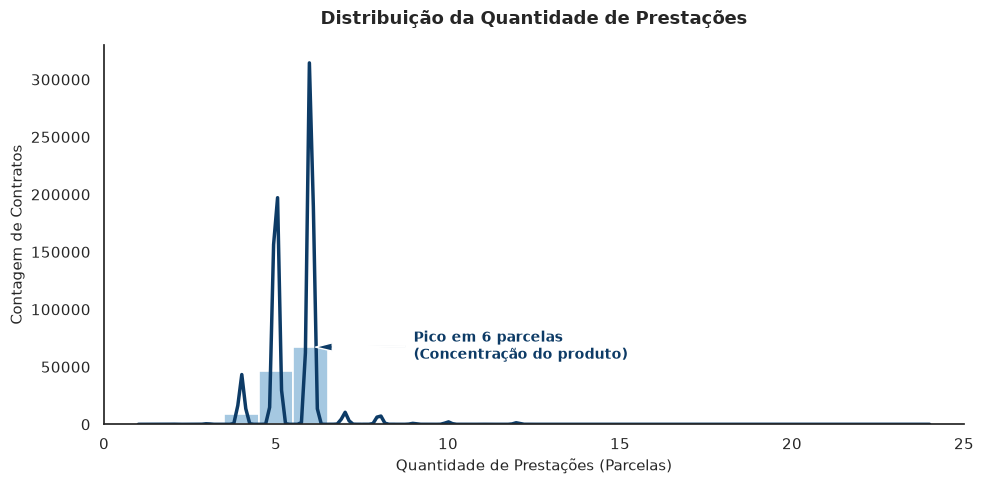

In [11]:
plt.figure(figsize=(10, 5))
sns.set_theme(style="white")

ax = sns.histplot(
    data=df,
    x='QT_PRS_APR',
    kde=True,
    discrete=True,  # Garante alinhamento nos inteiros
    color="#1f77b4",
    alpha=0.4,
    edgecolor="white",
    linewidth=1.2,
)

# Estilização da curva KDE
line = ax.lines[0]
line.set_color("#0d3b66")
line.set_linewidth(2.5)

# Títulos e formatação
plt.title(
    "Distribuição da Quantidade de Prestações",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Quantidade de Prestações (Parcelas)", fontsize=11)
plt.ylabel("Contagem de Contratos", fontsize=11)
plt.xlim(0, 25)

# Detalhe visual: anotação no pico (moda em 6 parcelas)
plt.annotate(
    "Pico em 6 parcelas\n(Concentração do produto)",
    xy=(6, df['QT_PRS_APR'].value_counts()[6]),
    xytext=(9, df['QT_PRS_APR'].value_counts()[6] * 0.85),
    arrowprops=dict(facecolor="#0d3b66", shrink=0.05, width=1, headwidth=6),
    fontsize=10,
    fontweight="bold",
    color="#0d3b66",
)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

- Exploração de Prazo de Pagamento Aprovado 

In [12]:
prazo_media = df['VR_PRZ_APR'].mean()

print(f"Prazo médio para pagamento é de: {prazo_media:.0f} dias")

Prazo médio para pagamento é de: 167 dias


--- adicionar analise de dispersão de graficos para prazo de pagamento aprovado

A análise da quantidade de prestações e do prazo aprovado revela o perfil operacional do produto de crédito da carteira:

- Foco no Curto Prazo: A operação é fortemente concentrada em ciclos curtos. As opções de 5 e 6 parcelas representam a grande maioria dos contratos (com a moda em 6 prestações). Contratos com 4 a 6 parcelas somam mais de 96% de toda a base.

- Variabilidade de Prazos: A amplitude da quantidade de prestações vai de 1 a 24 parcelas (2 anos), embora prazos superiores a 12 meses sejam casos pontuais/exceções na esteira de concessão.

- Média de Dias do Contrato: O prazo médio aprovado é de 167 dias (aproximadamente 5,5 meses). Esse valor é perfeitamente coerente com a média ponderada do número de parcelas (cerca de 5,6 prestações mensais), refletindo também pequenos ajustes de calendário e carências curtas até o vencimento da primeira parcela.

- Exploração do valor proposto e valor aprovado

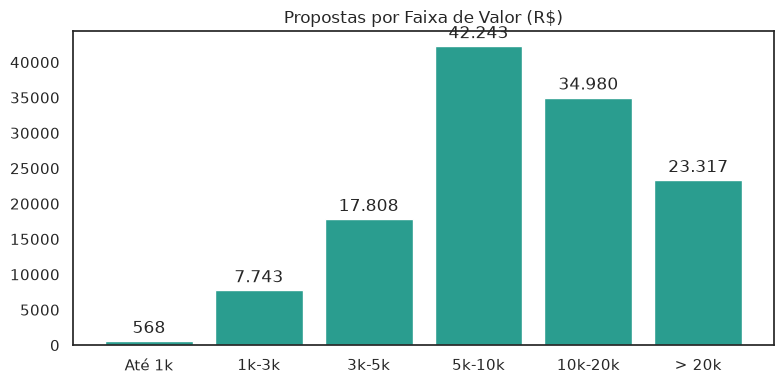

In [13]:
bins = [0, 1000, 3000, 5000, 10000, 20000, float("inf")]
labels = ["Até 1k", "1k-3k", "3k-5k", "5k-10k", "10k-20k", "> 20k"]

contagem = pd.cut(df["VR_SOL_PRP"], bins=bins, labels=labels).value_counts(sort=False)

plt.figure(figsize=(8, 4))
barras = plt.bar(contagem.index, contagem.values, color="#2a9d8f")

plt.title("Propostas por Faixa de Valor (R$)")
plt.bar_label(
    barras,
    labels=[f"{v:_}".replace("_", ".") for v in contagem.values],
    padding=3,
)

plt.tight_layout()
plt.show()

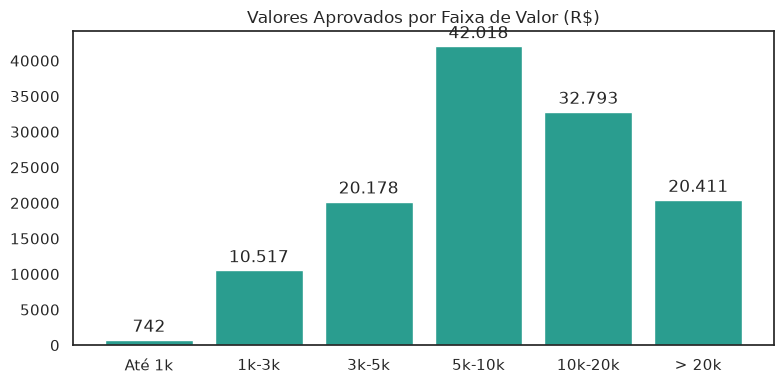

In [14]:
bins = [0, 1000, 3000, 5000, 10000, 20000, float("inf")]
labels = ["Até 1k", "1k-3k", "3k-5k", "5k-10k", "10k-20k", "> 20k"]

contagem = pd.cut(df["VR_APR_PRP"], bins=bins, labels=labels).value_counts(sort=False)

plt.figure(figsize=(8, 4))
barras = plt.bar(contagem.index, contagem.values, color="#2a9d8f")

plt.title("Valores Aprovados por Faixa de Valor (R$)")
plt.bar_label(
    barras,
    labels=[f"{v:_}".replace("_", ".") for v in contagem.values],
    padding=3,
)

plt.tight_layout()
plt.show()

Observamos que a os valores solicitados pelos clientes em sua maioria está na faixa de 5 à 20 mil reais, caracterizando contratos de grandes valores monetários e possivelmente de grande duração. Pode-se investigar no futuro a relação entre o valor solicitado e o valor aprovado para cada faixa como também uma avaliação cruzada entre a natureza de negócio, taxa de juros, inadimplência e dados demográficos dos clientes. 

- Exploração do tipo de proposta 

In [15]:
total_propostas_normais = len(df[df['ID_TP_PRP'] == 0])
total_propostas_renegociadas = len(df[df['ID_TP_PRP'] == 1])
total_propostas_refinanciadas = len(df[df['ID_TP_PRP'] == 2])
total_propostas = len(df['ID_TP_PRP'])

print(f"{total_propostas_normais} das propostas são normais")
print(f"Há {total_propostas_renegociadas} propostas que foram renegociadas")
print(f"Há {total_propostas_refinanciadas} propostas que foram refinanciadas")
print(" ")
print(f"{((total_propostas_normais/total_propostas)*100):.0f}% das propostas são normais")
print(f"{((total_propostas_renegociadas/total_propostas)*100):.0f}% das propostas foram renegociadas")
print(f"{((total_propostas_refinanciadas/total_propostas)*100):.0f}% das propostas são propostas refinanciadas")

92705 das propostas são normais
Há 32318 propostas que foram renegociadas
Há 1636 propostas que foram refinanciadas
 
73% das propostas são normais
26% das propostas foram renegociadas
1% das propostas são propostas refinanciadas


A maioria das propostas são propostas normais, ou seja, não houve necessidade de renegociação ou refinanciamento. Posteriormente podemos buscar entender se há alguma correlação entre os tipos de propostas e (1) os dados pessoais dos clientes, (2) o segmento de negócio, (3) informações de crédito dos clientes. Também podemos buscar analisar se o tipo de proposta possui algum relação com o valor aprovado. 

- Valor de juros aprovado

In [16]:
df['VR_JRS_APR'].describe()

count    126659.000000
mean        879.633356
std         774.484256
min           5.550000
25%         382.630000
50%         637.320000
75%        1093.540000
max       10063.200000
Name: VR_JRS_APR, dtype: float64

Observamos que em média, o valor pago de juros é de 879 reais. Apesar disso, a distribuição dos dados nos tras informações importantes acerca da política de crédito da empresa: muitos contratos com juros baixos/médios e poucos contratos com juros muito altos. Precisamos investigar se estes que possuem mais juros são de fato os contratos com maior valor aprovado ou prazo.

- Taxa de juros aprovado

In [17]:
df['TX_JRS_APR'].describe()

count    126659.000000
mean          1.981052
std           0.427038
min           0.950000
25%           1.450000
50%           2.300000
75%           2.300000
max           2.300000
Name: TX_JRS_APR, dtype: float64

As taxas de juros aparentam possuir um valor baixo e constante, independente do valor aprovado e tipo de contrato, de forma que metade dos contratos no dataset possui uma taxa de 2.3%, em modelos preditivos incluir essa variável pode trazer pouco poder discriminatório, podemos considerar seu descarte. 

### Dados de inadimplência

In [18]:
# Soma de dias em atraso (por parcela) - Soma de quantos dias teve de atraso no contrato todo
df['QT_DD_ACM_ATR'].describe()

count    126659.000000
mean          7.846312
std          32.384799
min           0.000000
25%           0.000000
50%           0.000000
75%           3.000000
max         569.000000
Name: QT_DD_ACM_ATR, dtype: float64

Observamos que 50% dos dados são menores ou iguais a zero, ou seja, a metade dos clientes nunca atrasou o pagamento de parcelas.
Em conjunto a isso, 75% dos dados são menores ou iguais a 3 e o valor máximo presente na tabela consiste em 569 dias. 

In [19]:
# Máximo de dias em atraso (por parcela) - Maior atraso que uma parcela teve
df['QT_DD_ACM_ATR_MAX'].describe()

count    126659.000000
mean          3.795309
std          13.075084
min           0.000000
25%           0.000000
50%           0.000000
75%           3.000000
max         299.000000
Name: QT_DD_ACM_ATR_MAX, dtype: float64

Considerando que a maior quantidade de dias que uma única parcela esteve atrasada é de 299 dias, e que em um determinado contrato houve no total 569 dias de pagamento atrasado, deduzimos que alguns dos devedores tem costume de atrasar o pagamento das parcelas. Podemos no futuro investigar essa relação ao tentar deduzir quantos clientes possuem tendência de serem inadimplentes. 

De acordo com esse blog do [Creditas](https://www.creditas.com/exponencial/como-inadimplencia-afeta-minha-vida/) e [CNN](https://www.cnnbrasil.com.br/economia/seu-bolso/meu-dinheiro/existe-um-prazo-para-que-dividas-sejam-registradas-entenda/#goog_rewarded), cada credor define o próprio critério interno para classificar uma dívida como inadimplência e, depois, decidir se e quando reporta o CPF aos órgãos de proteção. Em geral, esse ponto costuma ser em torno de 30 dias de atraso ou mais.

In [20]:
quantidade_inadimplencia = (df['QT_DD_ACM_ATR_MAX'] > 30).sum()
print(quantidade_inadimplencia)

3264


Há 3264 registros em que o máximo/maior de atraso de uma parcela foi maior que de 30 dias, considerando assim 3264 contratos que em algum momento podem ter vindo a se tornar inadimplentes. Isso representa em torno de 2% dos contratos presentes na base de dados. Decidi não investigar a coluna QT_DD_ACM_ATR pois ela sozinha não é um indicativo de se houve inadimplência ou não ao longo do contrato

### Dados do Micronegócio

Há disponível em nossa base de dados algumas informações e dados sobre o micronegócio. Alguns destes podem servir como proxy tanto para informações sensíveis dos devedores como para informações sobre saúde financeira e etc. Para manter o foco em justiça algorítmica e não desviarmos para um estudo a respeito da natureza de crédito simplesmente, acredito que dos dados disponíveis na base de dados, os que podem ser interessantes são a respeito da natureza do negócio. São listados em nossa base:

- Comércio Varejista de Artigos do Vestuário e Acessórios
- Comércio Varejista de Cosméticos e Perfumaria
- Bares, Restaurantes, Lanchonetes e Similares
- Comércio Varejista de Mercadorias em Geral, com Pred. de Produtos Alimentícios
- Serviços de Beleza e/ou Estética
- Demais atividades
- Atividade Mais Frequente

In [21]:
COLUNAS_ATIVIDADES = [
    "QT_ATV_CFC",
    "QT_ATV_CRL",
    "QT_ATV_BEB",
    "QT_ATV_ANI",
    "QT_ATV_PFM",
    "QT_ATV_OUT",
    "DE_ATV_FRQ"
]

In [22]:
df_atividades = df[COLUNAS_ATIVIDADES]
df_atividades

,QT_ATV_CFC,QT_ATV_CRL,QT_ATV_BEB,QT_ATV_ANI,QT_ATV_PFM,QT_ATV_OUT,DE_ATV_FRQ
0,0,0,2,0,0,2,Bares e lanchonetes
1,1,0,0,0,0,5,"Artigos usados, em lojas"
2,0,0,0,0,0,4,"Pecas, ornatos e estruturas cimento, gesso"
3,1,1,0,0,2,2,"Cabeleireiros, manicure e pedicure"
4,2,0,0,0,0,3,Roupas/agasalhos e pecas vestuario
...,...,...,...,...,...,...,...
126654,2,0,1,0,0,4,Roupas/agasalhos e pecas vestuario
126655,2,1,0,0,0,2,Roupas/agasalhos e pecas vestuario
126656,2,0,1,0,0,1,Roupas/agasalhos e pecas vestuario
126657,0,0,0,0,0,3,Prod.farmaceuticos e veterinarios


Os dados das atividades dizem respeito a quantidade de cada atividade de negócio foi indicada por grupos. Observei que cada grupo pode possuir 0 ou mais de zero atividades e a presença em determinado grupo não necessariamente exclui a presença de alguma atividade econômica em outro grupo. 

Pesquisando mais afundo me deparei com a ideia de CNAE (Classificação Nacional de Atividades Econômicas), um código que indica a atividade fim da empresa - cada empresa possui um CNAE principal e pode cadastrar até 99 CNAEs secundários. Esse excesso de CNAEs pode ajudar a evitar que o negócio seja multado por emitir nota fiscal de uma atividade não cadastrada caso decida expandir um pouco o cardápio no futuro.

In [23]:
df_atividades['DE_ATV_FRQ'].value_counts()

DE_ATV_FRQ
Roupas/agasalhos e pecas vestuario                                                     49063
Cosmeticos e prod.perfumaria                                                           18194
Comércio varejista de artigos do vestuário e acessórios                                 8247
Carnes - Acougues                                                                       5211
Frios, carnes, frutas e verduras                                                        4995
                                                                                       ...  
Moveis moldados de material plastico                                                       1
Comércio varejista de lubrificantes                                                        1
De aparelhos eletromédicos e eletroterapêuticos e equipamentos de irradiaçao               1
Prod.Ferro,Aco e Ferro-ligas em formas primarias e semi-acabados                           1
Fab. Artefatos Texteis de Tecidos, exceto vestuario ARTEF.P

Como além das colunas quantitativas, há uma coluna qualitativa descrevendo a atividade mais frequente (seria esse o CNAE principal? ou a atividade que tem maior fonte de receita), talvez seja interessante nos guiarmos pelas variáveis quantitativas tendo em vista que elas possivelmente já promovem um agrupamento e padronização das atividades econômicas das empresas. 

Digo isso pois por exemplo, há 20417 micronegócios em que a atividade mais frequente foi "Cosmeticos e prod. perfumaria" e 2553 micronegócios em que a atividade mais frequente foi "Prod. perfumaria", não seria mais simples uma análise em que os dois sejam da mesma natureza? Acredito que seria um pouco complicado buscar na base de dados todas as ocorrências de dados qualitativos que se assemelham. Ou também, nas situações em que há a distinção de "Comércio varejista de suvenires, bijuterias e artesanatos" e "Bijouterias", talvez ocorra uma segregação e perda de informação desnecessária em nossas análises devido a esse excesso de fragmentação pois por que o "Bijouterias" não se encaixa em  "Comércio varejista de suvenires, bijuterias e artesanatos" já que um está contido no outro? E também, e se há "Bijuterias" e "Bijouterias"? Pode vir a ter uma fragmentação maior ainda.